# Phase 1 — Model 2 · Encoder–decoder Transformer

Train on 512-word inputs and 128-word targets using the shared tokenizer.

## Required files and runtime

- Attach the saved `encdec_pairs_512_128/` folder, or attach the complete `phase1_scratch_data/` folder to prepare new pairs. New pair preparation uses the manifest, tokenizer, token streams, held-out files, and `documents.jsonl`.
- Attach `evaluate_phase1.py` for held-out scoring. Attach the official test prompt JSON or enable Internet and the authorized `HF_TOKEN` Kaggle secret.
- Use a GPU for training and generation. Attach the original run folder when resuming.

## 1. Setup and paths

In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'numpy', 'huggingface-hub', 'matplotlib'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'numpy', 'huggingface-hub', 'matplotlib'], returncode=0)

In [ ]:
import copy, gc, hashlib, heapq, json, math, os, random, re, shutil, time, zipfile
from collections import defaultdict
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from IPython.display import display, HTML

SOURCES = ('supreme_court', 'high_courts', 'acts', 'tribunals')
PAD, UNK, BOS, EOS = range(4)
VERSION = 'encdec-512w-128w-v1'

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    os.replace(tmp, path)

def digest_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(8 * 1024**2), b''): h.update(block)
    return h.hexdigest()

def atomic_save(value, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(value, str(path) + '.tmp')
    os.replace(str(path) + '.tmp', path)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(),
                torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [])

def restore_rng(s):
    random.setstate(s['python']); np.random.set_state(s['numpy']); torch.set_rng_state(s['torch'])
    if s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])


In [ ]:
def find_artifact_folder(input_root, kind, explicit=None):
    def matches(folder):
        try:
            m=read_json(folder/'manifest.json')
            if kind=='shared':
                required=['tokenizer.json','documents.jsonl','dev_prompts.json','dev_truth.json']
                required += [f'{s}.{split}.bin' for s in SOURCES for split in ('train','val')]
                return 'files' in m and all((folder/n).is_file() for n in required)
            return ('shards' in m and m.get('settings',{}).get('version')==VERSION
                    and all((folder/n).is_file() for n in ['tokenizer.json','settings.json','length_report.json','dev_prompts.json','dev_truth.json']))
        except (OSError,ValueError,TypeError): return False
    if explicit is not None:
        folder=Path(explicit)
        if not matches(folder): raise ValueError(f'Incomplete or incompatible {kind} artifacts: {folder}')
        return folder
    found=sorted({p.parent for p in Path(input_root).rglob('manifest.json') if matches(p.parent)})
    if len(found)>1:
        raise ValueError(f'Multiple {kind} folders found. Set the corresponding override explicitly: {found}')
    return found[0] if found else None


In [ ]:
INPUT_DATA_DIR = None  # e.g. Path('/kaggle/input/.../phase1_scratch_data')
INPUT_PAIR_DIR = None  # Later sessions: saved encdec_pairs_512_128 folder
RESUME_FROM = None     # Later sessions: saved encoder_decoder_500m folder

PAIR_OUTPUT = Path('/kaggle/working/encdec_pairs_512_128')
RUN_DIR = Path('/kaggle/working/encoder_decoder_500m_batch4_trial')
DEV_OUT = Path('/kaggle/working/encoder_decoder_dev')
TEST_OUT = Path('/kaggle/working/encoder_decoder_test')
TEST_PROMPTS = None
TEST_REVISION = "89edba6a44d6bb9593fd13b6895b5cd3b06eb82e"
MICRO_BATCH_PER_GPU = 4
GRADIENT_ACCUMULATION = 4
EVALUATOR_PATH = None  # None searches /kaggle/input for exactly one evaluate_phase1.py
REPO = 'Exploration-Lab/CS-781-Capstone'
SEED = 42

if INPUT_PAIR_DIR is None and (PAIR_OUTPUT/'manifest.json').exists():
    PAIR_DIR = find_artifact_folder('/kaggle/input','pairs',PAIR_OUTPUT)
else:
    PAIR_DIR = find_artifact_folder('/kaggle/input','pairs',INPUT_PAIR_DIR)
if PAIR_DIR is None:
    DATA_DIR = find_artifact_folder('/kaggle/input','shared',INPUT_DATA_DIR)
    if DATA_DIR is None:
        raise FileNotFoundError('Attach the extracted phase1_scratch_data files listed in A0, or previously prepared model-2 pairs. No complete artifacts found under /kaggle/input.')
    PAIR_DIR = PAIR_OUTPUT
else:
    DATA_DIR = Path(INPUT_DATA_DIR) if INPUT_DATA_DIR is not None else None

print('Original shared data:', DATA_DIR)
print('Model-2 pairs:', PAIR_DIR)
print('Writable model-2 run:', RUN_DIR)
print('Resume source:', RESUME_FROM)

if not os.environ.get('HF_TOKEN'):
    try:
        from kaggle_secrets import UserSecretsClient
        access_token=UserSecretsClient().get_secret('HF_TOKEN')
        if access_token: os.environ['HF_TOKEN']=access_token
    except Exception:
        pass

## 2. Tokenizer and paired data

In [ ]:
def split_bpe_pieces(text, max_chars=256):
    """Keep every character; separate words, punctuation and whitespace.

    An optional leading ASCII space can join a word or punctuation piece.
    Long pieces are split into bounded chunks to limit per-piece work.
    No normalization, strip(), split(), external tokenizer or regex package.
    """
    for match in re.finditer(' ?\\w+| ?[^\\w\\s]+|\\s+', text):
        piece = match.group(0)
        for start in range(0, len(piece), max_chars):
            yield piece[start:start + max_chars].encode('utf-8')


In [ ]:
def apply_bpe_merges(piece, merge_ranks):
    """Apply learned merges by rank, breaking occurrence ties left-to-right.

    Token IDs 0..3 are reserved. Byte b always has ID b+4. A linked list
    and a heap avoid repeatedly scanning every adjacent pair in a piece.
    """
    ids = [byte + 4 for byte in piece]
    size = len(ids)
    if size < 2 or not merge_ranks:
        return tuple(ids)
    previous = [i - 1 for i in range(size)]
    following = [i + 1 for i in range(size)]
    following[-1] = -1
    active = [True] * size
    queue = []

    def offer(left):
        if left < 0 or not active[left]:
            return
        right = following[left]
        if right < 0:
            return
        pair = (ids[left], ids[right])
        rank = merge_ranks.get(pair)
        if rank is not None:
            heapq.heappush(queue, (rank, left, right, pair[0], pair[1]))
    for left in range(size - 1):
        offer(left)
    while queue:
        rank, left, right, a, b = heapq.heappop(queue)
        if not active[left] or not active[right] or following[left] != right:
            continue
        if ids[left] != a or ids[right] != b:
            continue
        ids[left] = 260 + rank
        active[right] = False
        following[left] = following[right]
        if following[right] >= 0:
            previous[following[right]] = left
        offer(previous[left])
        offer(left)
    result = []
    position = 0
    while position >= 0:
        result.append(ids[position])
        position = following[position]
    return tuple(result)


In [ ]:
class ScratchByteBPE:
    """Our byte BPE vocabulary, encoder, decoder and JSON serialization.

    All base bytes and EVERY intermediate merge token are retained.
    Integer IDs identify symbols; concatenated decimal strings are never used.
    Literal '<s>' etc. in ordinary input are encoded as text, not control IDs.
    """
    FORMAT = 'handwritten-byte-bpe-v1'
    PATTERN = ' ?\\w+| ?[^\\w\\s]+|\\s+'

    def __init__(self, merges=None, max_piece_chars=256):
        self.specials = ['<pad>', '<unk>', '<s>', '</s>']
        self.max_piece_chars = max_piece_chars
        if not isinstance(max_piece_chars, int) or max_piece_chars < 1:
            raise ValueError('max_piece_chars must be a positive integer')
        self.merges = []
        self.merge_ranks = {}
        self.token_bytes = [None] * 4 + [bytes([b]) for b in range(256)]
        self._cache = {}
        for pair in merges or []:
            self.add_merge(tuple(pair))

    def add_merge(self, pair):
        if len(pair) != 2 or pair in self.merge_ranks:
            raise ValueError('Invalid or repeated merge pair')
        if any((type(token) is not int or not 4 <= token < len(self.token_bytes) for token in pair)):
            raise ValueError('A merge must reference earlier non-special token IDs')
        new_id = len(self.token_bytes)
        self.merge_ranks[pair] = len(self.merges)
        self.merges.append(pair)
        self.token_bytes.append(self.token_bytes[pair[0]] + self.token_bytes[pair[1]])
        self._cache.clear()
        return new_id

    def get_vocab_size(self):
        return len(self.token_bytes)

    def token_to_id(self, special):
        return self.specials.index(special) if special in self.specials else None

    def encode(self, text):
        if not isinstance(text, str):
            raise TypeError('encode expects a string')
        output = []
        for piece in split_bpe_pieces(text, self.max_piece_chars):
            encoded = self._cache.get(piece)
            if encoded is None:
                encoded = apply_bpe_merges(piece, self.merge_ranks)
                if len(self._cache) >= 65536:
                    self._cache.clear()
                self._cache[piece] = encoded
            output.extend(encoded)
        return SimpleNamespace(ids=output)

    def decode(self, ids, skip_special_tokens=True):
        chunks = []
        for value in ids:
            token = int(value)
            if not 0 <= token < len(self.token_bytes):
                raise ValueError(f'Unknown token ID: {token}')
            if token < 4:
                if not skip_special_tokens:
                    chunks.append(self.specials[token].encode('utf-8'))
            else:
                chunks.append(self.token_bytes[token])
        return b''.join(chunks).decode('utf-8', errors='replace')

    def save(self, path, training=None):
        payload = {'format': self.FORMAT, 'special_tokens': self.specials, 'byte_offset': 4, 'pattern': self.PATTERN, 'max_piece_chars': self.max_piece_chars, 'merges': self.merges, 'vocab_hex': [None if value is None else value.hex() for value in self.token_bytes]}
        if training is not None:
            payload['training'] = training
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(path.suffix + '.tmp')
        temporary.write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')
        temporary.replace(path)

    @classmethod
    def from_file(cls, path):
        payload = json.loads(Path(path).read_text(encoding='utf-8'))
        if payload.get('format') != cls.FORMAT:
            raise ValueError('This is not our handwritten BPE format. Use a fresh data directory and retrain the tokenizer/token arrays.')
        if payload.get('special_tokens') != ['<pad>', '<unk>', '<s>', '</s>']:
            raise ValueError('Special-token IDs do not match')
        if payload.get('byte_offset') != 4 or payload.get('pattern') != cls.PATTERN:
            raise ValueError('Byte mapping or splitting rules do not match')
        tokenizer = cls(payload['merges'], payload['max_piece_chars'])
        expected = [None if value is None else value.hex() for value in tokenizer.token_bytes]
        if payload.get('vocab_hex') != expected:
            raise ValueError('Vocabulary is inconsistent with the merge history')
        return tokenizer


In [ ]:
def verify_artifacts(root):
    manifest = read_json(root / 'manifest.json')
    assert digest_file(root / 'tokenizer.json') == manifest['tokenizer_sha256'], 'Tokenizer hash mismatch'
    assert (root / 'documents.jsonl').is_file(), 'Document index required: do not treat concatenated documents as one text'
    for name, info in manifest['files'].items():
        path = root / name
        assert path.stat().st_size == info['bytes'], f'Size mismatch: {name}'
        assert digest_file(path) == info['sha256'], f'Hash mismatch: {name}'
    return manifest


In [9]:
if (PAIR_DIR/'manifest.json').exists():
    saved_pairs=read_json(PAIR_DIR/'manifest.json')
    assert digest_file(PAIR_DIR/'tokenizer.json') == saved_pairs['settings']['tokenizer']
    TOKENIZER = ScratchByteBPE.from_file(PAIR_DIR/'tokenizer.json')
    print('Loading previously prepared model-2 pairs; original corpus is not needed for this session.')
else:
    MANIFEST = verify_artifacts(DATA_DIR)
    TOKENIZER = ScratchByteBPE.from_file(DATA_DIR / 'tokenizer.json')
assert TOKENIZER.get_vocab_size() <= 65536, 'Saved uint16 token arrays require vocabulary <= 65536'
for probe in ['Section 42: भारत ₹100.', 'a  b\n c', '<s> literal text']:
    assert TOKENIZER.decode(TOKENIZER.encode(probe).ids) == probe
print('Vocabulary:', TOKENIZER.get_vocab_size())
print('Saved data verified. No BPE training is needed.')
print('GPUs:', torch.cuda.device_count())
for i in range(torch.cuda.device_count()): print(i, torch.cuda.get_device_name(i))


Loading previously prepared model-2 pairs; original corpus is not needed for this session.
Vocabulary: 32768
Saved data verified. No BPE training is needed.
GPUs: 2
0 Tesla T4
1 Tesla T4


In [ ]:
def iter_word_pairs(root, tok, source, split):
    arr = np.memmap(root / f'{source}.{split}.bin', mode='r', dtype='<u2')
    try:
        with (root / 'documents.jsonl').open(encoding='utf-8') as f:
            for line in f:
                row = json.loads(line)
                if row['source'] != source or row['split'] != split: continue
                words = tok.decode(arr[row['start']:row['end']]).split()
                if row.get('document_token_start', 0) > 0: words = words[1:]
                if row.get('truncated', False): words = words[:-1]
                for start in range(0, len(words)-639, 640):
                    yield ' '.join(words[start:start+512]), ' '.join(words[start+512:start+640])
    finally:
        arr._mmap.close()

def resolve_test(path, repo):
    if path is not None:
        return Path(path)
    from huggingface_hub import hf_hub_download

    destination = Path("/kaggle/working/official_phase1_test.json")
    if not destination.is_file():
        downloaded = hf_hub_download(
            repo, "Phase_1_Pretraining/Test/test.json",
            repo_type="dataset", revision=TEST_REVISION,
        )
        shutil.copy2(downloaded, destination)
    return destination


def unique_pairs(items):
    out = {}
    for k, v in items:
        if k in out: raise ValueError(f'Duplicate JSON key: {k}')
        out[k] = v
    return out

def load_prompts(path):
    data = json.loads(Path(path).read_text(encoding='utf-8'), object_pairs_hook=unique_pairs)
    if not isinstance(data, dict) or not data: raise ValueError('Expected nonempty ID-to-record mapping')
    for k, v in data.items():
        if not isinstance(v, dict) or not isinstance(v.get('text'), str) or len(v['text'].split()) != 512:
            raise ValueError(f'Prompt {k} must contain exactly 512 words')
    return data

def length_report(root, tok, test_path, sample_per_source=250):
    lengths = []
    # Reservoir over up to 10,000 windows/source, bounded to avoid a full encoding pass.
    rng = random.Random(42)
    for source in SOURCES:
        sample = []
        for n, pair in enumerate(iter_word_pairs(root, tok, source, 'train')):
            if n >= 10000: break
            if n < sample_per_source: sample.append(pair)
            else:
                j = rng.randrange(n+1)
                if j < sample_per_source: sample[j] = pair
        lengths.extend((len(tok.encode(a).ids), len(tok.encode(b).ids)+1) for a,b in sample)
    if not lengths: raise ValueError('No complete 640-word training windows found')
    values = np.asarray(lengths)
    prompts = list(load_prompts(root / 'dev_prompts.json').values()) + list(load_prompts(test_path).values())
    prompt_lengths = [len(tok.encode(v['text']).ids) for v in prompts]
    refs = read_json(root / 'dev_truth.json')
    target_lengths = [len(tok.encode(v['text']).ids)+1 for v in refs.values()]
    report = dict(sample_examples=len(values), sampling='bounded reservoir; first 10000 windows/source',
        encoder_percentiles=dict(zip(['50','95','99','100'], np.percentile(values[:,0],[50,95,99,100]).tolist())),
        target_percentiles_including_eos=dict(zip(['50','95','99','100'], np.percentile(values[:,1],[50,95,99,100]).tolist())),
        max_dev_test_prompt_tokens=max(prompt_lengths), max_dev_target_tokens=max(target_lengths),
        suggested_encoder_limit=int(math.ceil(max(np.percentile(values[:,0],99),max(prompt_lengths))/128)*128),
        suggested_target_limit=int(math.ceil(max(np.percentile(values[:,1],99),max(target_lengths))/128)*128))
    return report

In [11]:
if (PAIR_DIR/'length_report.json').exists():
    LENGTH_REPORT = read_json(PAIR_DIR/'length_report.json')
else:
    TEST_PROMPTS = resolve_test(TEST_PROMPTS, REPO)
    LENGTH_REPORT = length_report(DATA_DIR, TOKENIZER, TEST_PROMPTS)
print(json.dumps(LENGTH_REPORT, indent=2))

test.json: 0.00B [00:00, ?B/s]

{
  "sample_examples": 1000,
  "sampling": "bounded reservoir; first 10000 windows/source",
  "encoder_percentiles": {
    "50": 627.0,
    "95": 742.05,
    "99": 858.0899999999999,
    "100": 1584.0
  },
  "target_percentiles_including_eos": {
    "50": 154.0,
    "95": 189.04999999999995,
    "99": 244.04999999999995,
    "100": 457.0
  },
  "max_dev_test_prompt_tokens": 1376,
  "max_dev_target_tokens": 298,
  "suggested_encoder_limit": 1408,
  "suggested_target_limit": 384
}


In [ ]:
ENCODER_LIMIT = LENGTH_REPORT['suggested_encoder_limit']
TARGET_LIMIT = LENGTH_REPORT['suggested_target_limit']  # includes target EOS
assert ENCODER_LIMIT >= LENGTH_REPORT['max_dev_test_prompt_tokens']
TOTAL_DATA_TOKENS = 500_000_000
MODEL_CONFIG = dict(vocab_size=TOKENIZER.get_vocab_size(), width=704,
                    encoder_layers=6, decoder_layers=8, heads=11, dropout=0.0)
TRAIN_CONFIG = dict(seed=SEED, total_data_tokens=TOTAL_DATA_TOKENS,
    micro_batch_per_gpu=MICRO_BATCH_PER_GPU, accumulation=GRADIENT_ACCUMULATION, lr=3e-4, min_lr=3e-5,
    warmup_fraction=0.03, weight_decay=0.1, clip=1.0,
    eval_every=250, save_every=100, log_every=10, validation_examples=256)

# A restored run must use its original configuration, not new defaults.
saved_run = Path(RESUME_FROM) if RESUME_FROM is not None else RUN_DIR
if (saved_run/'run_config.json').exists():
    saved_config=read_json(saved_run/'run_config.json')
    MODEL_CONFIG=saved_config['model']; TRAIN_CONFIG=saved_config['train']
    TOTAL_DATA_TOKENS=TRAIN_CONFIG['total_data_tokens']; SEED=TRAIN_CONFIG['seed']
    print('Restored model/training configuration from', saved_run)
if (PAIR_DIR/'settings.json').exists():
    pair_settings=read_json(PAIR_DIR/'settings.json')
    ENCODER_LIMIT=pair_settings['encoder_limit']; TARGET_LIMIT=pair_settings['target_limit']

In [ ]:
def prepare_pairs(root, out, tok, enc_limit, target_limit):
    out.mkdir(parents=True, exist_ok=True)
    signature = dict(version=VERSION, source_manifest=digest_file(root/'manifest.json'),
        document_index=digest_file(root/'documents.jsonl'), tokenizer=digest_file(root/'tokenizer.json'),
        encoder_limit=enc_limit, target_limit=target_limit, input_words=512, target_words=128)
    if (out/'settings.json').exists() and read_json(out/'settings.json') != signature:
        raise ValueError('Pair preparation settings changed. Use a new PAIR_DIR.')
    write_json(out/'settings.json', signature)
    reports = {}
    for split in ('train','val'):
        for source in SOURCES:
            stem = f'{source}.{split}'
            done = out/f'{stem}.json'
            if done.exists():
                reports[stem] = read_json(done)
                for name, info in reports[stem]['files'].items():
                    assert digest_file(out/name) == info['sha256'], f'Pair file damaged: {name}'
                print('Reusing', stem); continue
            rows = []; enc_offset = target_offset = skipped = 0
            with (out/f'{stem}.input.bin').open('wb') as a, (out/f'{stem}.target.bin').open('wb') as b:
                for prompt, target in iter_word_pairs(root,tok,source,split):
                    x, y = tok.encode(prompt).ids, tok.encode(target).ids
                    if len(x)>enc_limit or len(y)+1>target_limit:
                        skipped += 1; continue
                    np.asarray(x,dtype='<u2').tofile(a); np.asarray(y+[EOS],dtype='<u2').tofile(b)
                    rows.append((enc_offset,len(x),target_offset,len(y)+1))
                    enc_offset += len(x); target_offset += len(y)+1
                    if len(rows)%5000 == 0: print(stem, 'pairs:',len(rows),flush=True)
            np.save(out/f'{stem}.index.npy', np.asarray(rows,dtype=np.int64).reshape(-1,4))
            names = [f'{stem}.input.bin',f'{stem}.target.bin',f'{stem}.index.npy']
            reports[stem] = dict(examples=len(rows), over_limit_skipped=skipped,
                input_tokens=enc_offset,target_tokens=target_offset-len(rows),
                files={n:dict(bytes=(out/n).stat().st_size,sha256=digest_file(out/n)) for n in names})
            write_json(done,reports[stem])
    for name in ('tokenizer.json','dev_prompts.json','dev_truth.json'):
        shutil.copy2(root/name,out/name)
    manifest = dict(settings=signature,shards=reports)
    write_json(out/'manifest.json',manifest)
    print(json.dumps({k:{x:v for x,v in r.items() if x!='files'} for k,r in reports.items()},indent=2))
    return manifest


In [14]:
if (PAIR_DIR/'manifest.json').exists():
    PAIR_MANIFEST=read_json(PAIR_DIR/'manifest.json')
    print('Using complete existing pair data:',PAIR_DIR)
else:
    PAIR_MANIFEST = prepare_pairs(DATA_DIR, PAIR_DIR, TOKENIZER, ENCODER_LIMIT, TARGET_LIMIT)
    write_json(PAIR_DIR/'length_report.json', LENGTH_REPORT)
print('Save this preparation output for subsequent GPU sessions:', PAIR_DIR)


Using complete existing pair data: /kaggle/working/encdec_pairs_512_128
Save this preparation output for subsequent GPU sessions: /kaggle/working/encdec_pairs_512_128


In [ ]:
class PairData:
    def __init__(self, root, split, seed=42, budget=None, max_examples=None):
        self.root=Path(root); self.shards=[]; descriptors=[]
        for source in SOURCES:
            stem=f'{source}.{split}'
            index=np.load(self.root/f'{stem}.index.npy',mmap_mode='r')
            if not len(index): continue
            a=np.memmap(self.root/f'{stem}.input.bin',mode='r',dtype='<u2')
            b=np.memmap(self.root/f'{stem}.target.bin',mode='r',dtype='<u2')
            sid=len(self.shards); self.shards.append((source,index,a,b))
            descriptors.extend((sid,i) for i in range(len(index)))
        rng=np.random.default_rng(seed); rng.shuffle(descriptors)
        self.rows=[]; self.costs=[]; self.targets=[]; total=0
        capacity=sum(int(self.shards[s][1][i,1]+self.shards[s][1][i,3]-1) for s,i in descriptors)
        if budget is not None and capacity<budget:
            raise ValueError(f'Eligible capacity {capacity:,} < budget {budget:,}. Explicitly lower TOTAL_DATA_TOKENS; no data repeated.')
        for s,i in descriptors:
            _,nx,_,ny=self.shards[s][1][i]; cost=int(nx+ny-1)
            if budget is not None and total+cost>budget: break
            self.rows.append((s,i)); self.costs.append(cost); self.targets.append(int(ny))
            total+=cost
            if max_examples and len(self.rows)>=max_examples: break
        if not self.rows: raise ValueError('No selected training/validation pairs')
        self.total=total

    def __len__(self): return len(self.rows)

    def close(self):
        for _,index,a,b in self.shards:
            for array in (index,a,b): array._mmap.close()

    def batch(self, start, stop, device):
        chosen=self.rows[start:min(stop,len(self))]
        examples=[]
        for s,i in chosen:
            _,index,a,b=self.shards[s]; ox,nx,oy,ny=map(int,index[i])
            examples.append((a[ox:ox+nx],b[oy:oy+ny]))
        nx=max(len(a) for a,b in examples); ny=max(len(b) for a,b in examples)
        x=np.full((len(examples),nx),PAD,dtype=np.int64)
        d=np.full((len(examples),ny),PAD,dtype=np.int64)
        y=np.full((len(examples),ny),-100,dtype=np.int64)
        for j,(a,b) in enumerate(examples):
            x[j,:len(a)]=a; d[j,0]=BOS; d[j,1:len(b)]=b[:-1]; y[j,:len(b)]=b
        return tuple(torch.from_numpy(a).to(device) for a in (x,d,y))

    def report(self):
        mix=defaultdict(int)
        for (s,i),cost in zip(self.rows,self.costs): mix[self.shards[s][0]]+=cost
        return dict(examples=len(self),total_data_tokens=self.total,
            decoder_text_tokens=sum(self.targets)-len(self), source_tokens=dict(mix))


In [16]:
train_preview = PairData(PAIR_DIR,'train',SEED,budget=TOTAL_DATA_TOKENS)
print(json.dumps(train_preview.report(),indent=2))
train_preview.close()
del train_preview


{
  "examples": 623976,
  "total_data_tokens": 499999202,
  "decoder_text_tokens": 98504028,
  "source_tokens": {
    "supreme_court": 202836683,
    "high_courts": 89608832,
    "tribunals": 84737668,
    "acts": 122816019
  }
}


## 3. Model and correctness checks

In [ ]:
class Attention(nn.Module):
    def __init__(self,width,heads,dropout=0.0):
        super().__init__(); assert width%heads==0
        self.heads=heads; self.dim=width//heads; self.dropout=dropout
        self.q=nn.Linear(width,width); self.k=nn.Linear(width,width)
        self.v=nn.Linear(width,width); self.out=nn.Linear(width,width)

    def forward(self,x,memory=None,valid=None,causal=False,past=None,cache=False):
        b,t,w=x.shape
        def split(z): return z.view(b,-1,self.heads,self.dim).transpose(1,2)
        q=split(self.q(x))
        if memory is not None and past is not None:
            k,v=past
        else:
            source=x if memory is None else memory
            k,v=split(self.k(source)),split(self.v(source))
            if past is not None:
                k=torch.cat((past[0],k),dim=2); v=torch.cat((past[1],v),dim=2)
        mask=None
        if valid is not None: mask=valid[:,None,None,:]
        if causal:
            offset=k.shape[2]-t
            allowed=torch.arange(k.shape[2],device=x.device)[None,:] <= (torch.arange(t,device=x.device)+offset)[:,None]
            mask=allowed[None,None,:,:] if mask is None else mask & allowed[None,None,:,:]
        h=F.scaled_dot_product_attention(q,k,v,attn_mask=mask,
            dropout_p=self.dropout if self.training else 0.0)
        h=self.out(h.transpose(1,2).contiguous().view(b,t,w))
        return h, (k,v) if cache else None

class EncoderBlock(nn.Module):
    def __init__(self,w,h,p):
        super().__init__(); self.n1=nn.LayerNorm(w); self.n2=nn.LayerNorm(w)
        self.attn=Attention(w,h,p); self.drop=nn.Dropout(p)
        self.ff=nn.Sequential(nn.Linear(w,4*w),nn.GELU(),nn.Linear(4*w,w))
    def forward(self,x,valid):
        x=x+self.drop(self.attn(self.n1(x),valid=valid)[0])
        return x+self.drop(self.ff(self.n2(x)))

class DecoderBlock(nn.Module):
    def __init__(self,w,h,p):
        super().__init__(); self.n1=nn.LayerNorm(w); self.n2=nn.LayerNorm(w); self.n3=nn.LayerNorm(w)
        self.self_attn=Attention(w,h,p); self.cross=Attention(w,h,p); self.drop=nn.Dropout(p)
        self.ff=nn.Sequential(nn.Linear(w,4*w),nn.GELU(),nn.Linear(4*w,w))
    def forward(self,x,memory,source_valid,target_valid=None,past=None,cache=False):
        self_past,cross_past=(None,None) if past is None else past
        a,skv=self.self_attn(self.n1(x),valid=target_valid,causal=True,past=self_past,cache=cache)
        x=x+self.drop(a)
        a,ckv=self.cross(self.n2(x),memory=memory,valid=source_valid,past=cross_past,cache=cache)
        x=x+self.drop(a); x=x+self.drop(self.ff(self.n3(x)))
        return x, (skv,ckv) if cache else None


In [ ]:
class EncoderDecoder(nn.Module):
    def __init__(self,vocab_size=32768,width=704,encoder_layers=6,decoder_layers=8,heads=11,dropout=0.0):
        super().__init__()
        self.config=dict(vocab_size=vocab_size,width=width,encoder_layers=encoder_layers,
                         decoder_layers=decoder_layers,heads=heads,dropout=dropout)
        self.token=nn.Embedding(vocab_size,width)
        self.encoder=nn.ModuleList([EncoderBlock(width,heads,dropout) for _ in range(encoder_layers)])
        self.decoder=nn.ModuleList([DecoderBlock(width,heads,dropout) for _ in range(decoder_layers)])
        self.enc_norm=nn.LayerNorm(width); self.dec_norm=nn.LayerNorm(width)
        self.drop=nn.Dropout(dropout); self.gradient_checkpointing=True
        self.apply(self.initialize)

    @staticmethod
    def initialize(m):
        if isinstance(m,(nn.Linear,nn.Embedding)):
            nn.init.normal_(m.weight,std=0.02)
            if isinstance(m,nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)

    def embed(self,ids,offset=0):
        w=self.config['width']; positions=torch.arange(offset,offset+ids.shape[1],device=ids.device).float()
        frequency=torch.exp(torch.arange(0,w,2,device=ids.device).float()*(-math.log(10000)/w))
        angle=positions[:,None]*frequency[None,:]
        pe=torch.stack((angle.sin(),angle.cos()),dim=-1).flatten(1)[:,:w]
        return self.drop(self.token(ids)+pe.to(self.token.weight.dtype))

    def encode(self,src):
        valid=src.ne(PAD); x=self.embed(src)
        for block in self.encoder:
            if self.training and self.gradient_checkpointing:
                x=checkpoint(block,x,valid,use_reentrant=False)
            else: x=block(x,valid)
        return self.enc_norm(x),valid

    def decode(self,ids,memory,source_valid,past=None,cache=False):
        offset=0 if past is None else past[0][0][0].shape[2]
        x=self.embed(ids,offset)
        valid=ids.ne(PAD) if past is None else None
        caches=[]
        for i,block in enumerate(self.decoder):
            if self.training and self.gradient_checkpointing:
                x=checkpoint(lambda a,b,c,d,layer=block: layer(a,b,c,d)[0],
                    x,memory,source_valid,valid,use_reentrant=False)
            else:
                x,kv=block(x,memory,source_valid,valid,None if past is None else past[i],cache)
                if cache: caches.append(kv)
        return self.dec_norm(x),caches

    def forward(self,src,decoder_ids,labels=None):
        memory,valid=self.encode(src); h,_=self.decode(decoder_ids,memory,valid)
        if labels is None: return F.linear(h,self.token.weight)
        flat=h.reshape(-1,h.shape[-1]); labels=labels.reshape(-1)
        def loss_chunk(a,b):
            return F.cross_entropy(F.linear(a,self.token.weight).float(),b,ignore_index=-100,reduction='sum')
        loss=h.new_zeros((),dtype=torch.float32)
        for start in range(0,len(labels),128):
            a,b=flat[start:start+128],labels[start:start+128]
            loss=loss+(checkpoint(loss_chunk,a,b,use_reentrant=False) if self.training else loss_chunk(a,b))
        return loss

class ParallelLoss(nn.Module):
    def __init__(self,model): super().__init__(); self.model=model
    def forward(self,x,d,y):
        with torch.autocast(device_type=x.device.type,dtype=torch.float16,enabled=x.is_cuda):
            return self.model(x,d,y)


In [ ]:
def check_model():
    seed_all(7)
    m=EncoderDecoder(vocab_size=300,width=16,encoder_layers=1,decoder_layers=1,heads=2).eval()
    src=torch.tensor([[5,6,7]]); d=torch.tensor([[BOS,8,9,10]])
    with torch.no_grad():
        logits=m(src,d)
        changed=d.clone(); changed[0,-1]=11
        torch.testing.assert_close(logits[:,:-1],m(src,changed)[:,:-1],atol=1e-6,rtol=1e-5)
        padded=F.pad(src,(0,2),value=PAD)
        torch.testing.assert_close(logits,m(padded,d),atol=1e-6,rtol=1e-5)
        memory,valid=m.encode(src); past=None
        for i in range(d.shape[1]):
            h,past=m.decode(d[:,i:i+1],memory,valid,past,True)
            torch.testing.assert_close(F.linear(h,m.token.weight)[:,0],logits[:,i],atol=1e-6,rtol=1e-5)
    m.train(); loss=m(src,d,torch.tensor([[8,9,10,EOS]])); loss.backward()
    assert torch.isfinite(loss)
    assert m.encoder[0].attn.q.weight.grad.abs().sum()>0
    print('Passed: causality, padding, KV cache, and encoder gradients.')


In [22]:
check_model()
with torch.device('meta'):
    preview = EncoderDecoder(**MODEL_CONFIG)
parameters = sum(p.numel() for p in preview.parameters())
assert 50_000_000 <= parameters <= 300_000_000
print(f'Parameters: {parameters:,}')
del preview


Passed: causality, padding, KV cache, and encoder gradients.
Parameters: 122,356,608


## 4. Training and checkpoints

The main run uses four examples per GPU and four accumulation passes. To reproduce the earlier one-example trial, use its own `RUN_DIR` and set the microbatch and accumulation to 1 and 16. A restored run uses the configuration saved with its checkpoint.

In [ ]:
def learning_rate(tokens,total,cfg):
    warm=max(1,int(total*cfg['warmup_fraction']))
    if tokens<warm: return cfg['lr']*max(1,tokens)/warm
    progress=min(1,max(0,(tokens-warm)/max(1,total-warm)))
    return cfg['min_lr']+(cfg['lr']-cfg['min_lr'])*0.5*(1+math.cos(math.pi*progress))

def make_session(pair_dir,run_dir,model_cfg,train_cfg,cpu=False):
    pair_dir,run_dir=Path(pair_dir),Path(run_dir); run_dir.mkdir(parents=True,exist_ok=True)
    if not cpu and not torch.cuda.is_available(): raise RuntimeError('Enable GPU before training')
    device=torch.device('cpu' if cpu else 'cuda')
    gpus=0 if cpu else torch.cuda.device_count()
    manifest=read_json(pair_dir/'manifest.json')
    for shard in manifest['shards'].values():
        for name,info in shard['files'].items():
            assert digest_file(pair_dir/name)==info['sha256'], f'Damaged pair artifact: {name}'
    assert digest_file(pair_dir/'tokenizer.json')==manifest['settings']['tokenizer']
    signature=dict(version=VERSION,model=model_cfg,train=train_cfg,gpus=gpus,
                   pair_manifest=digest_file(pair_dir/'manifest.json'))
    config_path=run_dir/'run_config.json'
    if config_path.exists() and read_json(config_path)!=signature:
        raise ValueError('Resume configuration mismatch. Restore original settings or use a new run folder.')
    if not config_path.exists() and any(run_dir.iterdir()): raise ValueError('Nonempty run folder without configuration')
    write_json(config_path,signature)
    shutil.copy2(pair_dir/'tokenizer.json',run_dir/'tokenizer.json')
    seed_all(train_cfg['seed'])
    train=PairData(pair_dir,'train',train_cfg['seed'],budget=train_cfg['total_data_tokens'])
    val=PairData(pair_dir,'val',train_cfg['seed'],max_examples=train_cfg['validation_examples'])
    model=EncoderDecoder(**model_cfg).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=train_cfg['lr'],weight_decay=train_cfg['weight_decay'])
    scaler=torch.amp.GradScaler('cuda',enabled=not cpu)
    wrapper=ParallelLoss(model)
    if gpus>1: wrapper=nn.DataParallel(wrapper)
    s=SimpleNamespace(out=run_dir,model=model,wrapper=wrapper,optimizer=optimizer,scaler=scaler,
        device=device,train=train,val=val,cfg=train_cfg,signature=signature,
        batch=train_cfg['micro_batch_per_gpu']*max(1,gpus),position=0,step=0,
        tokens=0,target_tokens=0,best=float('inf'),tokenizer_hash=manifest['settings']['tokenizer'])
    if (run_dir/'latest.pt').exists():
        saved=torch.load(run_dir/'latest.pt',map_location='cpu',weights_only=False)
        if saved['signature']!=signature: raise ValueError('Checkpoint signature mismatch')
        model.load_state_dict(saved['model']); optimizer.load_state_dict(saved['optimizer']); scaler.load_state_dict(saved['scaler'])
        for key in ('position','step','tokens','target_tokens','best'): setattr(s,key,saved[key])
        restore_rng(saved['rng'])
    write_json(run_dir/'selected_data.json',train.report())
    return s

def save_session(s):
    state=dict(model=s.model.state_dict(),model_config=s.model.config,signature=s.signature,
        optimizer=s.optimizer.state_dict(),scaler=s.scaler.state_dict(),rng=rng_state(),
        tokenizer_sha256=s.tokenizer_hash)
    state.update({k:getattr(s,k) for k in ('position','step','tokens','target_tokens','best')})
    atomic_save(state,s.out/'latest.pt')
    write_json(s.out/'progress.json',dict(step=s.step,examples=s.position,
        total_data_tokens=s.tokens,decoder_target_tokens_with_eos=s.target_tokens,
        selected_total_tokens=s.train.total,complete=s.position==len(s.train)))

def log_row(s,**values):
    row=dict(step=s.step,total_data_tokens=s.tokens,decoder_target_tokens_with_eos=s.target_tokens,**values)
    with (s.out/'metrics.jsonl').open('a',encoding='utf-8') as f: f.write(json.dumps(row)+'\n')
    if "val_loss" in row or row["step"] <= 1 or row["step"] % 100 == 0:
        print(row,flush=True)

@torch.inference_mode()
def validate(s):
    saved_rng=rng_state(); s.model.eval(); loss=count=0
    try:
        for start in range(0,len(s.val),s.batch):
            x,d,y=s.val.batch(start,start+s.batch,s.device)
            loss+=float(s.wrapper(x,d,y).sum()); count+=int(y.ne(-100).sum())
        value=loss/count
        if not math.isfinite(value): raise RuntimeError('Non-finite validation loss')
        log_row(s,val_loss=value,perplexity=math.exp(min(value,80)))
        if value<s.best:
            s.best=value
            atomic_save(dict(model=s.model.state_dict(),model_config=s.model.config,
                step=s.step,tokens=s.tokens,val_loss=value,tokenizer_sha256=s.tokenizer_hash,
                signature=s.signature),s.out/'best.pt')
        return value
    finally:
        restore_rng(saved_rng); s.model.train()

def train_update(s):
    end=min(len(s.train),s.position+s.batch*s.cfg['accumulation'])
    count=sum(s.train.targets[s.position:end]); consumed=sum(s.train.costs[s.position:end])
    lr=learning_rate(s.tokens,s.train.total,s.cfg)
    for group in s.optimizer.param_groups: group['lr']=lr
    for retry in range(5):
        s.optimizer.zero_grad(set_to_none=True); total_loss=0.0
        for start in range(s.position,end,s.batch):
            x,d,y=s.train.batch(start,min(end,start+s.batch),s.device)
            loss=s.wrapper(x,d,y).sum(); total_loss+=float(loss.detach())
            s.scaler.scale(loss/count).backward()
        s.scaler.unscale_(s.optimizer)
        norm=torch.nn.utils.clip_grad_norm_(s.model.parameters(),s.cfg['clip'])
        if not s.scaler.is_enabled() and not torch.isfinite(norm): raise RuntimeError('Non-finite CPU gradients')
        old_scale=s.scaler.get_scale(); s.scaler.step(s.optimizer); s.scaler.update()
        if s.scaler.get_scale()>=old_scale: break
        print('FP16 overflow: retrying the same examples with reduced scale.',flush=True)
    else: raise RuntimeError('Repeated FP16 overflow; checkpoint position was not advanced')
    s.position=end; s.tokens+=consumed; s.target_tokens+=count; s.step+=1
    return total_loss/count,consumed,lr

def train_session(pair_dir,run_dir,model_cfg,train_cfg,additional_steps=None,max_hours=10.5,cpu=False):
    s=make_session(pair_dir,run_dir,model_cfg,train_cfg,cpu)
    try:
        if s.step==0: validate(s); save_session(s)
        start_step=s.step; start_tokens=s.tokens; started=time.monotonic(); updates_seconds=0.0
        while s.position<len(s.train):
            if additional_steps is not None and s.step-start_step>=additional_steps: break
            if time.monotonic()-started>=max_hours*3600: break
            t=time.monotonic(); loss,consumed,lr=train_update(s)
            if s.device.type=='cuda': torch.cuda.synchronize()
            updates_seconds+=time.monotonic()-t
            if s.step%train_cfg['log_every']==0 or s.step==start_step+1:
                speed=(s.tokens-start_tokens)/max(time.monotonic()-started,1e-9)
                log_row(s,train_loss=loss,lr=lr,total_tokens_per_second=speed,
                        estimated_remaining_hours=(s.train.total-s.tokens)/speed/3600)
            if s.step%train_cfg['eval_every']==0: validate(s); save_session(s)
            elif s.step%train_cfg['save_every']==0: save_session(s)
        validate(s); save_session(s)
        elapsed=time.monotonic()-started
        done=s.tokens-start_tokens
        report=dict(steps=s.step-start_step,total_tokens=done,session_seconds=elapsed,
            update_tokens_per_second=done/max(updates_seconds,1e-9),
            session_tokens_per_second=done/max(elapsed,1e-9),
            estimated_remaining_hours=(s.train.total-s.tokens)/max(done/max(elapsed,1e-9),1e-9)/3600,
            complete=s.position==len(s.train))
        write_json(s.out/'last_session_report.json',report); print(json.dumps(report,indent=2))
        return report
    finally:
        s.train.close(); s.val.close()
        del s; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


In [ ]:
if RESUME_FROM is not None:
    origin=Path(RESUME_FROM)
    assert (origin/'latest.pt').is_file()
    if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
        raise ValueError('RUN_DIR is already populated; resume it directly or use a fresh destination.')
    shutil.copytree(origin,RUN_DIR,dirs_exist_ok=True)
print('Training checkpoints:',RUN_DIR)


### Initial 30-step benchmark

In [26]:
if not (RUN_DIR / "latest.pt").is_file():
    benchmark = train_session(PAIR_DIR,RUN_DIR,MODEL_CONFIG,TRAIN_CONFIG,
                              additional_steps=30,max_hours=1.0)

{'step': 0, 'total_data_tokens': 0, 'decoder_target_tokens_with_eos': 0, 'val_loss': 10.50078751179132, 'perplexity': 36344.11282474713}
{'step': 1, 'total_data_tokens': 25232, 'decoder_target_tokens_with_eos': 4959, 'train_loss': 10.511876882625025, 'lr': 2.00000320000512e-11, 'total_tokens_per_second': 20667.675075342475, 'estimated_remaining_hours': 6.719752358552694}
{'step': 10, 'total_data_tokens': 258365, 'decoder_target_tokens_with_eos': 51106, 'train_loss': 10.112985678368707, 'lr': 4.653247445195912e-06, 'total_tokens_per_second': 18992.104680367425, 'estimated_remaining_hours': 7.3091898714187735}
{'step': 20, 'total_data_tokens': 515715, 'decoder_target_tokens_with_eos': 102068, 'train_loss': 9.34160700427771, 'lr': 9.816835706937131e-06, 'total_tokens_per_second': 18674.603672850328, 'estimated_remaining_hours': 7.42963093012076}
{'step': 30, 'total_data_tokens': 771147, 'decoder_target_tokens_with_eos': 152537, 'train_loss': 9.050701433884198, 'lr': 1.4896743834790135e-05

### Optional maximum-length batch-4 memory check

Set the flag in the check cell to run the memory test after the benchmark.

In [ ]:
def test_maximum_training_memory():
    checkpoint_path = RUN_DIR / "latest.pt"
    assert checkpoint_path.is_file(), "Batch-4 checkpoint not found."
    assert torch.cuda.is_available(), "Enable GPU first."

    saved_rng = rng_state()
    model = wrapper = optimizer = scaler = saved = None
    x = decoder_input = targets = loss = None
    error_message = None
    success = False

    gc.collect()
    torch.cuda.empty_cache()

    try:
        saved = torch.load(
            checkpoint_path, map_location="cpu", weights_only=False
        )
        settings = saved["signature"]["train"]
        gpu_count = torch.cuda.device_count()

        assert gpu_count == saved["signature"]["gpus"], (
            "GPU count differs from the benchmark."
        )
        assert settings["micro_batch_per_gpu"] == 4

        batch_size = gpu_count * settings["micro_batch_per_gpu"]
        accumulation = settings["accumulation"]
        encoder_length = int(ENCODER_LIMIT)
        target_length = int(TARGET_LIMIT)

        print(
            f"Testing {gpu_count} GPUs × 4 examples/GPU\n"
            f"Encoder length: {encoder_length}\n"
            f"Decoder length: {target_length}\n"
            f"Accumulation passes: {accumulation}",
            flush=True,
        )

        model = EncoderDecoder(**saved["model_config"]).cuda()
        model.load_state_dict(saved["model"])
        model.train()

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=settings["lr"],
            weight_decay=settings["weight_decay"],
        )
        optimizer.load_state_dict(saved["optimizer"])

        scaler = torch.amp.GradScaler("cuda")
        scaler.load_state_dict(saved["scaler"])

        wrapper = ParallelLoss(model)
        if gpu_count > 1:
            wrapper = nn.DataParallel(wrapper)

        del saved
        saved = None

        # Every position is valid: no short examples or padding.
        vocab_size = model.config["vocab_size"]
        x = torch.randint(
            4, vocab_size, (batch_size, encoder_length), device="cuda"
        )
        targets = torch.randint(
            4, vocab_size, (batch_size, target_length), device="cuda"
        )
        targets[:, -1] = EOS

        decoder_input = torch.empty_like(targets)
        decoder_input[:, 0] = BOS
        decoder_input[:, 1:] = targets[:, :-1]

        for gpu in range(gpu_count):
            torch.cuda.synchronize(gpu)
            torch.cuda.reset_peak_memory_stats(gpu)

        optimizer.zero_grad(set_to_none=True)
        denominator = batch_size * target_length * accumulation

        for index in range(accumulation):
            loss = wrapper(x, decoder_input, targets).sum()
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss in the memory test.")

            scaler.scale(loss / denominator).backward()
            print(
                f"Maximum-length backward pass "
                f"{index + 1}/{accumulation} completed.",
                flush=True,
            )

        scaler.unscale_(optimizer)
        gradient_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), settings["clip"]
        )
        if not torch.isfinite(gradient_norm):
            raise RuntimeError(
                "Non-finite gradients on synthetic inputs; "
                "memory fit alone is inconclusive."
            )

        # Temporary model only. Includes optimizer-step memory usage.
        scaler.step(optimizer)
        scaler.update()

        for gpu in range(gpu_count):
            torch.cuda.synchronize(gpu)

        success = True

    except torch.cuda.OutOfMemoryError:
        error_message = (
            "OUT OF MEMORY: batch 4 did not fit at maximum lengths. "
            "Do not start the full batch-4 run."
        )
    except Exception as error:
        error_message = f"{type(error).__name__}: {error}"

    finally:
        for gpu in range(torch.cuda.device_count()):
            total = torch.cuda.get_device_properties(gpu).total_memory
            peak_used = torch.cuda.max_memory_allocated(gpu)
            peak_reserved = torch.cuda.max_memory_reserved(gpu)
            print(
                f"GPU {gpu}: peak tensor memory {peak_used / 2**30:.2f} GiB; "
                f"peak PyTorch reserved {peak_reserved / 2**30:.2f} GiB; "
                f"total {total / 2**30:.2f} GiB"
            )

        loss = x = decoder_input = targets = None
        wrapper = model = optimizer = scaler = saved = None
        gc.collect()
        torch.cuda.empty_cache()
        restore_rng(saved_rng)

    if success:
        print(
            "\nPASS: maximum-length batch 4 completed forward, backward, "
            "and optimizer step. Saved checkpoints were not modified."
        )
    else:
        print("\nTEST DID NOT PASS:", error_message)

In [27]:
CHECK_MAXIMUM_MEMORY = False
if CHECK_MAXIMUM_MEMORY:
    test_maximum_training_memory()

Testing 2 GPUs × 4 examples/GPU
Encoder length: 1408
Decoder length: 384
Accumulation passes: 4
Maximum-length backward pass 1/4 completed.
Maximum-length backward pass 2/4 completed.
Maximum-length backward pass 3/4 completed.
Maximum-length backward pass 4/4 completed.
GPU 0: peak tensor memory 2.79 GiB; peak PyTorch reserved 2.95 GiB; total 14.56 GiB
GPU 1: peak tensor memory 0.88 GiB; peak PyTorch reserved 1.00 GiB; total 14.56 GiB

PASS: maximum-length batch 4 completed forward, backward, and optimizer step. Saved checkpoints were not modified.


### Full training or resume

In [28]:
training_report = train_session(PAIR_DIR,RUN_DIR,MODEL_CONFIG,TRAIN_CONFIG,
                                additional_steps=None,max_hours=10.5)


{'step': 31, 'total_data_tokens': 796873, 'decoder_target_tokens_with_eos': 157561, 'train_loss': 8.925074097457205, 'lr': 1.542296467674348e-05, 'total_tokens_per_second': 19478.92996151652, 'estimated_remaining_hours': 7.118836295683013}
{'step': 40, 'total_data_tokens': 1027552, 'decoder_target_tokens_with_eos': 203359, 'train_loss': 8.830309164921205, 'lr': 2.0044052070483308e-05, 'total_tokens_per_second': 19338.60998552848, 'estimated_remaining_hours': 7.167176762695512}
{'step': 50, 'total_data_tokens': 1284824, 'decoder_target_tokens_with_eos': 253822, 'train_loss': 8.60160119735572, 'lr': 2.5189720303552483e-05, 'total_tokens_per_second': 19067.93030393681, 'estimated_remaining_hours': 7.265170863251218}
{'step': 60, 'total_data_tokens': 1541728, 'decoder_target_tokens_with_eos': 305129, 'train_loss': 8.418771888469827, 'lr': 3.0324288518861627e-05, 'total_tokens_per_second': 19179.968259540332, 'estimated_remaining_hours': 7.219011396203571}
{'step': 70, 'total_data_tokens': 

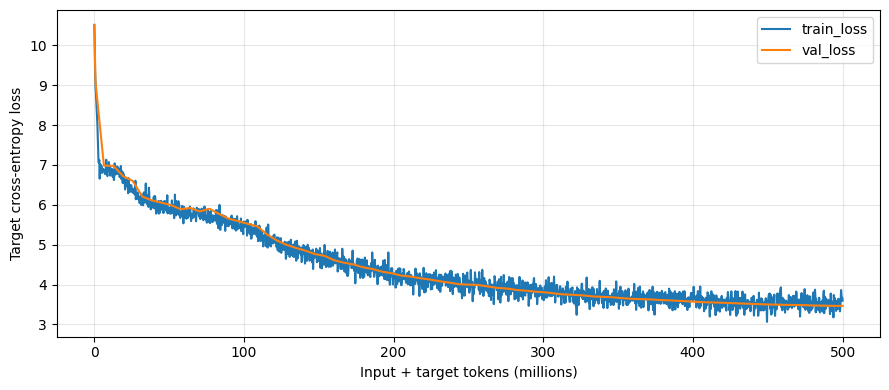

In [1]:
import matplotlib.pyplot as plt
rows=[json.loads(line) for line in (RUN_DIR/'metrics.jsonl').read_text().splitlines()]
fig,ax=plt.subplots(figsize=(9,4))
for key in ('train_loss','val_loss'):
    selected=[r for r in rows if key in r]
    ax.plot([r['total_data_tokens']/1e6 for r in selected],[r[key] for r in selected],label=key)
ax.set(xlabel='Input + target tokens (millions)',ylabel='Target cross-entropy loss')
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(RUN_DIR/'loss_curve.png',dpi=150); plt.show()


## 5. Generate and evaluate

Use the selected `best.pt`. Choose a fresh output directory when changing a recorded decoding policy. The main policy matches the saved test export.

In [ ]:
GENERATION_CHECKPOINT = RUN_DIR / "best.pt"
DECODE_CONFIG = dict(temperatures=[0.0, 0.1, 0.5, 0.8], top_p=0.95,
                     max_new_tokens=4096, no_repeat_ngram=4, seed=42)

In [ ]:
class IncompleteGeneration(RuntimeError): pass

def blocked_tokens(tokens,n):
    if len(tokens)<n-1: return set()
    prefix=tuple(tokens[-(n-1):])
    return {tokens[i+n-1] for i in range(len(tokens)-n+1) if tuple(tokens[i:i+n-1])==prefix}

@torch.inference_mode()
def generate_one(model,tok,prompt,device,cfg,seed):
    ids=tok.encode(prompt).ids
    if not ids: raise ValueError('Empty prompt')
    src=torch.tensor([ids],device=device)
    with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type=='cuda'):
        memory,valid=model.encode(src)
    attempts=[]
    for attempt,temperature in enumerate(cfg['temperatures']):
        torch.manual_seed((seed+attempt)%2**32)
        new=[]; past=None; x=torch.tensor([[BOS]],device=device)
        followers=defaultdict(set); n=cfg['no_repeat_ngram']
        for _ in range(cfg['max_new_tokens']):
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type=='cuda'):
                h,past=model.decode(x,memory,valid,past,True)
                logits=F.linear(h[:,-1],model.token.weight)[0].float()
            if not torch.isfinite(logits).all(): raise RuntimeError('Non-finite generation logits')
            logits[[PAD,UNK,BOS,EOS]]=-float('inf')
            if len(new)>=n-1:
                banned=followers.get(tuple(new[-(n-1):]),())
                if banned: logits[list(banned)]=-float('inf')
            if not torch.isfinite(logits).any(): break
            if temperature==0: nxt=int(logits.argmax())
            else:
                probs=torch.softmax(logits/temperature,dim=-1)
                probs,order=probs.sort(descending=True)
                probs[probs.cumsum(0)-probs>cfg['top_p']]=0
                nxt=int(order[torch.multinomial(probs,1)])
            new.append(nxt)
            if len(new)>=n: followers[tuple(new[-n:-1])].add(new[-1])
            words=tok.decode(new).split()
            if len(words)>=129:
                return ' '.join(words[:128]),dict(temperature=temperature,attempt=attempt+1,
                    generated_tokens=len(new),prior_failures=attempts)
            x=torch.tensor([[nxt]],device=device)
        attempts.append(dict(temperature=temperature,generated_tokens=len(new),words=len(tok.decode(new).split())))
        del past
    raise IncompleteGeneration(json.dumps(attempts))

def validate_predictions(predictions,prompts):
    if set(predictions)!=set(prompts): raise ValueError('Prediction IDs do not match prompt IDs')
    for k,v in predictions.items():
        if not isinstance(v,dict) or not isinstance(v.get('text'),str) or len(v['text'].split())!=128:
            raise ValueError(f'Prediction {k} must contain exactly 128 words')

def generate_set(checkpoint_path,run_dir,prompts_path,out,cfg,cpu=False):
    checkpoint_path,run_dir,prompts_path,out=map(Path,(checkpoint_path,run_dir,prompts_path,out))
    if cfg['no_repeat_ngram']<2 or not 0<cfg['top_p']<=1 or not cfg['temperatures'] or min(cfg['temperatures'])<0:
        raise ValueError('Invalid generation settings')
    prompts=load_prompts(prompts_path); out.mkdir(parents=True,exist_ok=True)
    signature=dict(version=VERSION,checkpoint=digest_file(checkpoint_path),
        tokenizer=digest_file(run_dir/'tokenizer.json'),prompts=digest_file(prompts_path),decode=cfg)
    if (out/'generation.json').exists():
        if read_json(out/'generation.json')!=signature: raise ValueError('Generation settings changed; use a new output folder')
    elif any(out.iterdir()): raise ValueError('Nonempty output folder without generation metadata')
    write_json(out/'generation.json',signature)
    ledger=read_json(out/'records.json') if (out/'records.json').exists() else {}
    if not set(ledger)<=set(prompts): raise ValueError('Unknown saved IDs')
    for k,r in ledger.items(): validate_predictions({k:{'text':r['text']}},{k:prompts[k]})
    device=torch.device('cpu' if cpu else 'cuda')
    if not cpu and not torch.cuda.is_available(): raise RuntimeError('Enable GPU for generation')
    state=torch.load(checkpoint_path,map_location='cpu',weights_only=False)
    if state['tokenizer_sha256']!=signature['tokenizer']: raise ValueError('Checkpoint/tokenizer mismatch')
    model=EncoderDecoder(**state['model_config']); model.load_state_dict(state['model']); del state
    model.to(device).eval(); tok=ScratchByteBPE.from_file(run_dir/'tokenizer.json')
    failures={}
    try:
        for key,record in prompts.items():
            if key in ledger: continue
            seed=(cfg['seed']+int(hashlib.sha256(key.encode()).hexdigest()[:8],16))%2**32
            try:
                text,details=generate_one(model,tok,record['text'],device,cfg,seed)
            except IncompleteGeneration as error:
                failures[key]=str(error); write_json(out/'failures.json',failures)
                print('Could not finish ID',key,'; continuing other prompts.',flush=True); continue
            ledger[key]=dict(text=text,details=details)
            write_json(out/'records.json',ledger)
            write_json(out/'prediction.json',{k:{'text':v['text']} for k,v in ledger.items()})
            if len(ledger)%100==0: print(f'Generated {len(ledger)}/{len(prompts)}',flush=True)
        write_json(out/'failures.json',failures)
        predictions={k:{'text':v['text']} for k,v in ledger.items()}
        if len(predictions)!=len(prompts):
            print(f'INCOMPLETE: {len(predictions)}/{len(prompts)}. No submission ZIP created. See failures.json.')
            return None
        validate_predictions(predictions,prompts)
        write_json(out/'prediction.json',predictions)
        archive=out/'submission.zip'
        with zipfile.ZipFile(str(archive)+'.tmp','w',compression=zipfile.ZIP_DEFLATED) as z:
            z.write(out/'prediction.json','prediction.json')
        with zipfile.ZipFile(str(archive)+'.tmp') as z:
            assert z.namelist()==['prediction.json'] and z.testzip() is None
            validate_predictions(json.loads(z.read('prediction.json'),object_pairs_hook=unique_pairs),prompts)
        os.replace(str(archive)+'.tmp',archive)
        print(f'Validated {len(predictions)} continuations, 128 words each: {archive}')
        return archive
    finally:
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()


### Development predictions and official evaluation

In [ ]:
dev_archive = generate_set(GENERATION_CHECKPOINT,RUN_DIR,
                           PAIR_DIR/'dev_prompts.json',DEV_OUT,DECODE_CONFIG)


In [ ]:
subprocess.run([sys.executable,'-m','pip','install','-q','bert-score==0.3.13','transformers>=4.45,<5'],check=True)
if EVALUATOR_PATH is None:
    candidates=list(Path('/kaggle/input').rglob('evaluate_phase1.py'))
    if len(candidates)!=1: raise ValueError(f'Set EVALUATOR_PATH explicitly. Found: {candidates}')
    EVALUATOR_PATH=candidates[0]
validate_predictions(read_json(DEV_OUT/'prediction.json'),load_prompts(PAIR_DIR/'dev_prompts.json'))
command=[sys.executable,str(EVALUATOR_PATH),'--truth',str(PAIR_DIR/'dev_truth.json'),
         '--prediction',str(DEV_OUT/'prediction.json')]
result=subprocess.run(command,capture_output=True,text=True)
print(result.stdout)
if result.returncode and result.stderr: print(result.stderr)
(DEV_OUT/'prof_evaluation.txt').write_text(result.stdout+'\n'+result.stderr,encoding='utf-8')
write_json(DEV_OUT/'evaluator_provenance.json',dict(script_sha256=digest_file(EVALUATOR_PATH),
    truth_sha256=digest_file(PAIR_DIR/'dev_truth.json'),prediction_sha256=digest_file(DEV_OUT/'prediction.json'),returncode=result.returncode))
result.check_returncode()


Examples: 212
BERTScore F1: 0.810088
ROUGE-L F1:   0.164026
BLEU-4:       0.025561



### Test submission

In [12]:
TEST_PROMPTS = resolve_test(TEST_PROMPTS, REPO)
test_archive = generate_set(
    GENERATION_CHECKPOINT,
    RUN_DIR,
    TEST_PROMPTS,
    TEST_OUT,
    DECODE_CONFIG,
)

Generated 10/1000
Generated 20/1000
Generated 30/1000
Generated 40/1000
Generated 50/1000
Generated 60/1000
Generated 70/1000
Generated 80/1000
Generated 90/1000
Generated 100/1000
Generated 110/1000
Generated 120/1000
Generated 130/1000
Generated 140/1000
Generated 150/1000
Generated 160/1000
Generated 170/1000
Generated 180/1000
Generated 190/1000
Generated 200/1000
Generated 210/1000
Generated 220/1000
Generated 230/1000
Generated 240/1000
Generated 250/1000
Generated 260/1000
Generated 270/1000
Generated 280/1000
Generated 290/1000
Generated 300/1000
Generated 310/1000
Generated 320/1000
Generated 330/1000
Generated 340/1000
Generated 350/1000
Generated 360/1000
Generated 370/1000
Generated 380/1000
Generated 390/1000
Generated 400/1000
Generated 410/1000
Generated 420/1000
Generated 430/1000
Generated 440/1000
Generated 450/1000
Generated 460/1000
Generated 470/1000
Generated 480/1000
Generated 490/1000
Generated 500/1000
Generated 510/1000
Generated 520/1000
Generated 530/1000
Ge

In [ ]:
import base64
validate_predictions(read_json(TEST_OUT/'prediction.json'),load_prompts(TEST_PROMPTS))
archive=TEST_OUT/'submission.zip'
assert archive.is_file()
with zipfile.ZipFile(archive) as z:
    assert z.namelist()==['prediction.json'] and z.testzip() is None
    validate_predictions(json.loads(z.read('prediction.json')),load_prompts(TEST_PROMPTS))
encoded=base64.b64encode(archive.read_bytes()).decode('ascii')
display(HTML(f'<a download="encoder_decoder_submission.zip" href="data:application/zip;base64,{encoded}">Download submission ZIP</a>'))


Download submission ZIP

### Alternative decoding policy

The separate temperature-0.1 dev trial used `[0.1, 0.5, 0.8]`. To reproduce it, set that list in `DECODE_CONFIG` and point `DEV_OUT` at a separate folder before running the dev prediction and evaluation cells. The earlier setup also specified `[0.1, 0.3, 0.5]`.